# Regresión Lineal: Pulse vs Maxpulse
Este notebook implementa un modelo de **regresión lineal simple** usando `scikit-learn` para analizar la relación entre la frecuencia cardíaca promedio (*Pulse*) y la frecuencia cardíaca máxima (*Maxpulse*).


### **Manejo de datos:**

1. Leer el archivo ```data.csv``` y verificar que no tenga valores nulos, mostrar su cantidad de filas y columnas, tipos de datos e imprimir los 5 primeros registros.

2. Separando la información:
2.1 Separar los datos en Input (X) y Output (y), para el Input seleccionar las columnas Pulse y Maxpulse.
2.2 Separar los datos en Train y Test, dejar 80% de datos para entrenamiento
3. Crear un modelo de regresión lineal simple y entrenarlo usando LinearRegresion()

**4**. Obtener los coeficientes $\theta_{0}$  y $\theta_{}1$ de  la recta de ajuste., tal que  $y=\theta_{1}x +\theta_{0}$  y el error cuadrático.

## Importación de librerías

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

## Cargar datos de ejemplo
Para esta demostración usaremos un dataset simple con columnas `Pulse` y `Maxpulse`. En un caso real, deberías cargar tus propios datos.

In [2]:
data= pd.read_csv('data/fitness.csv')
data

,Duration,Pulse,Maxpulse,Calories
0,60,110,130,409.1
1,60,117,145,479.0
2,60,103,135,340.0
3,45,109,175,282.4
4,45,117,148,406.0
...,...,...,...,...
164,60,105,140,290.8
165,60,110,145,300.0
166,60,115,145,310.2
167,75,120,150,320.4


## Preparación de los datos

In [3]:
X = data['Pulse']
y = data['Maxpulse']

# Convertir a arrays de numpy con forma adecuada
x1 = np.array(X).reshape(-1, 1)
y1 = np.array(y).reshape(-1, 1)

x1[:5], y1[:5]

(array([[110],
        [117],
        [103],
        [109],
        [117]]),
 array([[130],
        [145],
        [135],
        [175],
        [148]]))

## División en entrenamiento y prueba

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    x1, y1, test_size=0.2, random_state=42
)

X_train.shape, X_test.shape

((135, 1), (34, 1))

## Entrenamiento del modelo

In [5]:
model_1 = LinearRegression()
model_1.fit(X_train, y_train)

print('Coeficiente (pendiente):', model_1.coef_)
print('Intercepto:', model_1.intercept_)

Coeficiente (pendiente): [[0.87563409]]
Intercepto: [40.14853251]


## Evaluación del modelo

In [6]:
y_pred = model_1.predict(X_train)

print("Mean Squared Error (MSE):", mean_squared_error(y_train, y_pred))
print("R² Score:", r2_score(y_train, y_pred))

Mean Squared Error (MSE): 109.42959239825777
R² Score: 0.5927658494043987


## Visualización de la recta de regresión

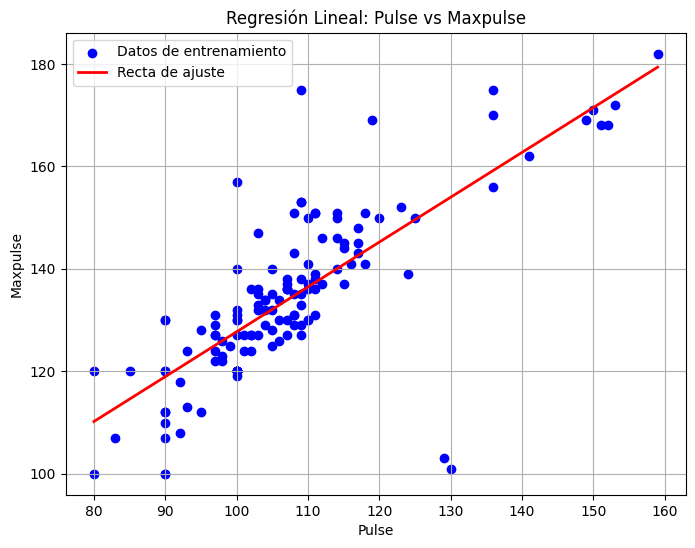

In [7]:
plt.figure(figsize=(8, 6))
plt.scatter(X_train, y_train, color='blue', label='Datos de entrenamiento')

# Generar puntos para la recta
x_line = np.linspace(X_train.min(), X_train.max(), 100).reshape(-1, 1)
y_line = model_1.predict(x_line)

plt.plot(x_line, y_line, color='red', linewidth=2, label='Recta de ajuste')
plt.xlabel('Pulse')
plt.ylabel('Maxpulse')
plt.title('Regresión Lineal: Pulse vs Maxpulse')
plt.legend()
plt.grid(True)
plt.show()